## Exemple simple de Graph

In [9]:
from typing import TypedDict
from pydantic import BaseModel
from langchain_core.messages import AnyMessage
from typing_extensions import TypedDict, Literal
from langchain_core.messages import AIMessage

In [11]:
class State(TypedDict):

    messages: list[str]
    counter: int
    
class State(BaseModel):
    messages: list[str]
    counter: int

from dataclasses import dataclass
@dataclass
class State:
    messages: list[str]
    counter: int
    
class State(TypedDict):
    messages: list[AnyMessage]
    counter: int

def node(state: State):
    messages = state["messages"]
    new_message = AIMessage("Hello!")
    return {"message": messages + [new_message], "counter": 10}

In [13]:
from langgraph.graph import StateGraph, START, END

workflow = StateGraph(State)
workflow.add_node("node1", node)
workflow.add_edge(START,"node1")
workflow.add_edge("node1",END)


In [14]:
graph=workflow.compile()

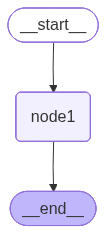

In [15]:
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

## Exemple de Graph Conditionnel

In [16]:
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END

In [21]:
class EmployeeState(TypedDict):
    name: str
    age: int
    salary: float
    decision: Literal["standard_hr", "forced_hr"]
    result: str

def analyze_employee(state: EmployeeState):

    if state["age"] <= 30 and state["salary"] <= 40000:
        state["decision"] = "standard_hr"
    else:
        state["decision"] = "forced_hr"

    return state

def standard_hr_process(state: EmployeeState):

    state["result"] = (
        f"Demande de {state['name']} envoyée au traitement RH standard"
    )

    return state

def standard_hr_process(state:EmployeeState):
    state['result'] = f"""Demande de {state['name']}
    envoyée au traitement RH standard"""
    return state

def forced_HR_validation(state:EmployeeState):
    state['result'] = f"""Demande de {state['name']}
    envoyée à la validation RH forcée"""
    return state

def router(state: EmployeeState):
    return state["decision"]

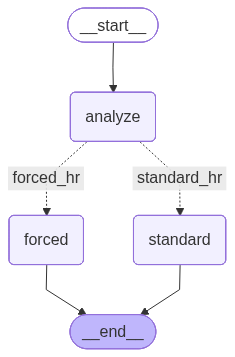

In [22]:
wf = StateGraph(EmployeeState)
wf.add_node("analyze", analyze_employee)
wf.add_node("standard", standard_hr_process)
wf.add_node("forced", forced_HR_validation)
wf.add_edge(START, "analyze")
wf.add_conditional_edges(
    "analyze",
    router, {
        "standard_hr":"standard",
        "forced_hr":"forced"
    }
)
graph = wf.compile()
display(Image(graph.get_graph().draw_mermaid_png()))

## Exemple de Graph avec Loop

In [25]:
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END

# 1) Etat partagé
class AdministrativeFileState(TypedDict):
    name:str
    remaining_documents:int
    reminders:int
    status:Literal["incomplete","complete","validated"]
# 2) Noeud de vérification
def verify_employee_file(state:AdministrativeFileState):
    if state['remaining_documents']>0:
        state['status']='incomplete'
    else:
        state['status']='complete'
        print("*"*50)
        print(f"Checking {state['name']}'s file, current status : {state['status']}")
    return state

def notify_employee(state : AdministrativeFileState):
    state['reminders']+=1
    if(state['remaining_documents'])>0:
        state['remaining_documents']-=1
        print("-"*50)
        print(f"Notification {state['reminders']} of employee {state['name']}")
        print(f"Remaining Documents : {state['remaining_documents']}")
    return state

def validate_file(state:AdministrativeFileState):
    state['status']="validated"
    print("="*40)
    print(f"Administrative File of {state['name']} succefully validated")
    return state

def router(state:AdministrativeFileState)->Literal['notify','validate']:
    if state['status']=='incomplete':
        return "notify"
    else:
        return "validate"

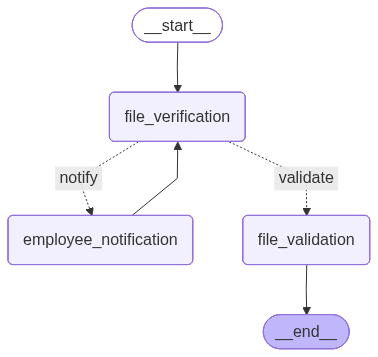

In [26]:
# 6) Construction du graphe
workflow = StateGraph(AdministrativeFileState)
workflow.add_node("file_verification",verify_employee_file)
workflow.add_node("employee_notification",notify_employee)
workflow.add_node("file_validation",validate_file)
workflow.set_entry_point("file_verification")
workflow.add_conditional_edges(
    "file_verification",
    router, {
        "notify":"employee_notification",
        "validate":"file_validation"
}

)
workflow.add_edge("employee_notification","file_verification")

graph = workflow.compile()
display(Image(graph.get_graph().draw_mermaid_png()))

In [27]:
resp = graph.invoke({
    "name":"Mohamed",
    "remaining_documents":4,
    "reminders":0}
)

--------------------------------------------------
Notification 1 of employee Mohamed
Remaining Documents : 3
--------------------------------------------------
Notification 2 of employee Mohamed
Remaining Documents : 2
--------------------------------------------------
Notification 3 of employee Mohamed
Remaining Documents : 1
--------------------------------------------------
Notification 4 of employee Mohamed
Remaining Documents : 0
**************************************************
Checking Mohamed's file, current status : complete
Administrative File of Mohamed succefully validated


In [1]:
from typing import Annotated, TypedDict
from langchain_core.tools import tool
from langchain_core.messages import HumanMessage
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.graph import StateGraph, START, END

# Remplacez par le LLM que vous utilisez (Ollama, ChatOpenAI, Groq, etc.)
from langchain_groq import ChatGroq

# 1. Définition de l'état (MessagesState est standard pour les agents)
class AgentState(TypedDict):
    messages: Annotated[list, add_messages]

# 2. Définition des outils (À remplacer par vos tools du TP8)
@tool
def get_weather(location: str) -> str:
    """Retourne la météo pour une ville donnée."""
    return f"Il fait beau et 25°C à {location}."

@tool
def calculate(a: int, b: int) -> int:
    """Multiplie deux nombres."""
    return a * b

tools = [get_weather, calculate]
tool_node = ToolNode(tools)

# 3. Initialisation du LLM et liaison avec les outils
llm = ChatGroq(model="llama-3.3-70b-versatile", temperature= 0) # Modifiez avec votre modèle/clé API
llm_with_tools = llm.bind_tools(tools)

# 4. Noeud principal de l'agent
def agent_node(state: AgentState):
    # L'agent invoque le LLM avec l'historique des messages
    response = llm_with_tools.invoke(state["messages"])
    return {"messages": [response]}

c:\Users\ATRARI\Desktop\ENIAD\2ème année\S8\TPs\SMA\TP9\.venv\Lib\site-packages\langgraph\cache\base\__init__.py:8: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
  from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer


In [2]:
# 5. Construction du Graph
workflow = StateGraph(AgentState)

# Ajout des noeuds
workflow.add_node("agent", agent_node)
workflow.add_node("tools", tool_node)

# Ajout des arêtes (edges)
workflow.add_edge(START, "agent")

# Ajout d'une arête conditionnelle :
# Si l'agent décide d'utiliser un outil, on va vers "tools", sinon vers "END"
workflow.add_conditional_edges(
    "agent",
    tools_condition,
    {
        "tools": "tools",
        END: END
    }
)

# Après l'exécution de l'outil, on retourne toujours à l'agent pour qu'il analyse la réponse
workflow.add_edge("tools", "agent")

# Compilation
agent_graph = workflow.compile()

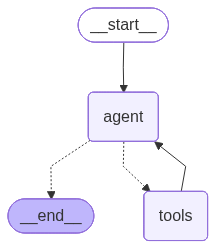

In [3]:
# Visualiser le graphe de l'Agent
from IPython.display import Image, display

display(Image(agent_graph.get_graph().draw_mermaid_png()))

In [4]:
# 6. Exécution et test du Workflow
inputs = {
    "messages": [
        HumanMessage(content="Peux-tu me donner la météo à Oujda et me calculer 5 multiplié par 8 ?")
    ]
}

# On utilise stream pour observer les étapes de raisonnement de l'agent
for chunk in agent_graph.stream(inputs, stream_mode="values"):
    chunk["messages"][-1].pretty_print()

================================ Human Message =================================

Peux-tu me donner la météo à Oujda et me calculer 5 multiplié par 8 ?


AuthenticationError: Error code: 401 - {'error': {'message': 'Invalid API Key', 'type': 'invalid_request_error', 'code': 'invalid_api_key'}}